# **Performing Gray Level Transformations for Image Enhancement**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [26]:

from pathlib import Path

# Find the Images folder
IMG_DIR = None

for candidate in [
    Path.cwd() / "Images",
    Path.cwd() / "images",
    Path.cwd().parent / "Images",
    Path.cwd().parent / "images"
]:
    if candidate.is_dir():
        IMG_DIR = candidate.resolve()
        break

# Check and display the path and contents
if IMG_DIR is None or not any(IMG_DIR.iterdir()):
    print("Images/ folder not found or empty.")
else:
    print("Image folder path:", IMG_DIR)
    print("\nFiles inside the folder:")
    for p in sorted(IMG_DIR.iterdir()):
        print(p.name)


Image folder path: D:\ai ml by ifty\image  processing\Images

Files inside the folder:
Bright.PNG
clock2.jpg
dark.jpg
Dark.PNG
fingerprint.jpg
gradient.png
High Contrast.PNG
horse-dog.jpg
lena_color.jpg
lenna.png
logo.png
Low Contrast - Shortcut.lnk
Low Contrast.PNG
lowcontrast.jpg
noisy.png
rgb.jpg
road.bmp
shapes.png
tagore.png
text.png


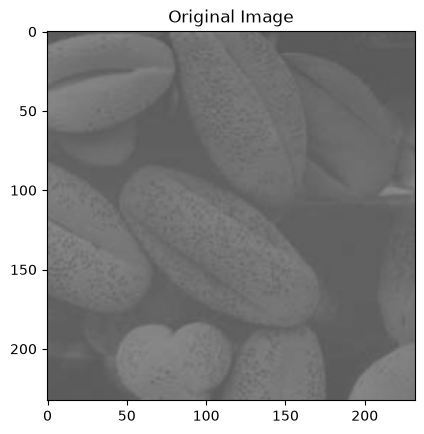

In [27]:
# Importing the Libraries & Loading the Image
import cv2
import matplotlib.pyplot as plt
import numpy as np
import warnings
from pathlib import Path

# Automatically find the root "Images" folder from week 2
IMG_DIR = None
for candidate in [Path.cwd() / "Images", Path.cwd() / "images", Path.cwd().parent / "Images", Path.cwd().parent / "images"]:
    if candidate.is_dir():
        IMG_DIR = candidate.resolve()
        break

image = cv2.imread(str(IMG_DIR / "Low Contrast.PNG"), cv2.IMREAD_GRAYSCALE)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title('Original Image')
plt.show()

<>:6: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
<>:6: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_19528\747818264.py:6: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
  image = cv2.imread('/ai ml by ifty\image  processing\Images/Low Contrast.PNG', cv2.IMREAD_GRAYSCALE)


Text(0.5, 1.0, 'Original Image')

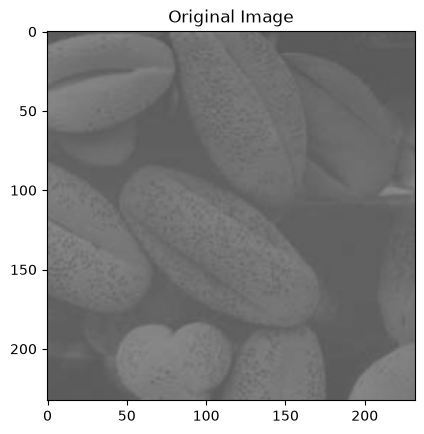

In [28]:
# Importing the Libraries & Loading the Image
import cv2
import matplotlib.pyplot as plt
import numpy as np
import warnings
image = cv2.imread('/ai ml by ifty\image  processing\Images/Low Contrast.PNG', cv2.IMREAD_GRAYSCALE)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title('Original Image')

**Image Negative**
* A negative of an image or inverted is computed using the following formula:<br>
    **s = (L – 1) – r**<br>
Where, r is the input image pixel, L is the highest value of the pixel and s is the resulting pixel.

In [29]:
# Negative Transformation Formula
negative = 255 - image

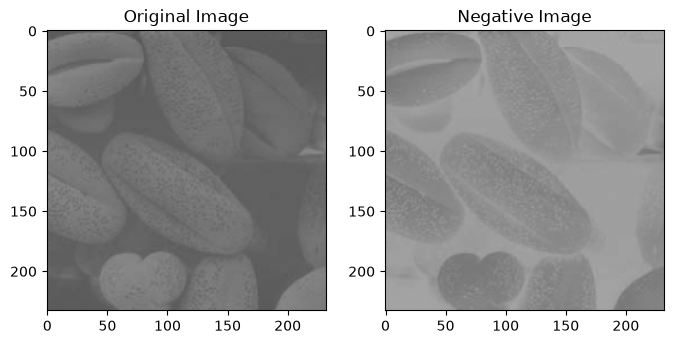

In [30]:
# Displaying Results
fig = plt.figure(figsize=(8, 8))
ax1 = fig.add_subplot(221)
ax2 = fig.add_subplot(222)
ax1.imshow(image, cmap='gray', vmin=0, vmax=255)
ax1.title.set_text('Original Image')
ax2.imshow(negative, cmap='gray', vmin=0, vmax=255)
ax2.title.set_text('Negative Image')

**Image Negative Using For Loop**

In [31]:
negative_image = np.zeros_like(image)

In [32]:
for i in range(image.shape[0]):
  for j in range(image.shape[1]):
    new_pixel = 255 - image[i,j]
    negative_image[i,j] = new_pixel

[[ 91  91  91 ...  92  94  94]
 [ 91  91  91 ...  91  92  92]
 [ 91  91  91 ...  93  92  92]
 ...
 [ 91  91  91 ... 122 122 121]
 [ 91  91  91 ... 122 122 121]
 [ 92  92  92 ... 122 122 121]]
[[164 164 164 ... 163 161 161]
 [164 164 164 ... 164 163 163]
 [164 164 164 ... 162 163 163]
 ...
 [164 164 164 ... 133 133 134]
 [164 164 164 ... 133 133 134]
 [163 163 163 ... 133 133 134]]


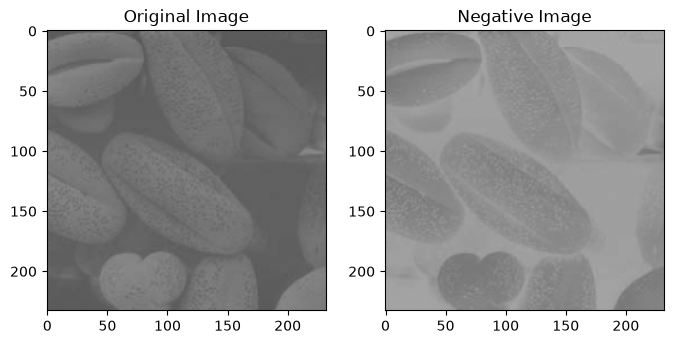

In [33]:
# Displaying Results
fig = plt.figure(figsize=(8, 8))
ax1 = fig.add_subplot(221)
ax2 = fig.add_subplot(222)
ax1.imshow(image, cmap='gray', vmin=0, vmax=255)
ax1.title.set_text('Original Image')
ax2.imshow(negative_image, cmap='gray', vmin=0, vmax=255)
ax2.title.set_text('Negative Image')
print(image)
print(negative_image)

**Log Transformation**
* During log transformation, the dark pixels in an image are expanded as compare to the higher pixel values.
The log transformation of an image is computed using the following formula:



*   **c=255/log(1+maximum intensity value)**
*   **s=c*log(1+r)**






In [34]:
# Log Transformation
c = round(255 / np.log(1 + np.max(image)))
log_image = c * (np.log(1+image))
log_image = np.array(log_image, dtype = np.uint8)

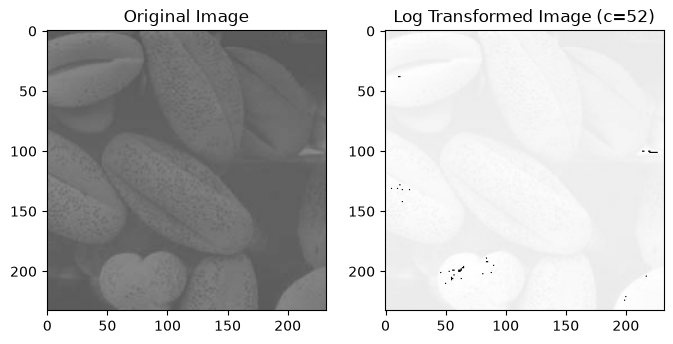

In [35]:
#Displaying Results
fig = plt.figure(figsize=(8, 8))
ax1 = fig.add_subplot(221)
ax2 = fig.add_subplot(222)
ax1.imshow(image, cmap='gray', vmin=0, vmax=255)
ax1.title.set_text('Original Image')
ax2.imshow(log_image, cmap='gray', vmin=0, vmax=255)
ax2.title.set_text(f'Log Transformed Image (c={c})')
plt.show()

**Log Transformation Using For Loop**

In [36]:
c = 255 / np.log(1 + np.max(image))
log_image = np.zeros_like(image)
for i in range(image.shape[0]):
    for j in range(image.shape[1]):
         new_pixel = c * np.log(1 + image[i,j])
         log_image[i,j] = new_pixel

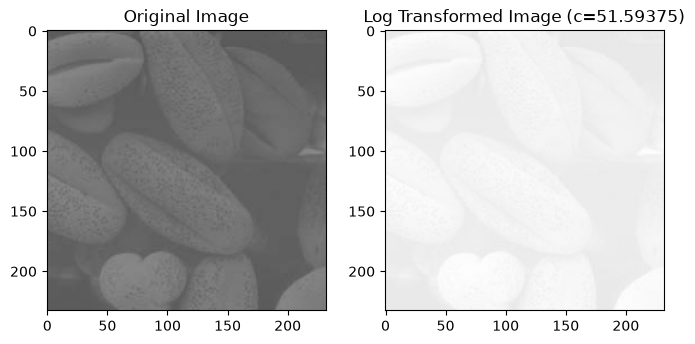

[[ 91  91  91 ...  92  94  94]
 [ 91  91  91 ...  91  92  92]
 [ 91  91  91 ...  93  92  92]
 ...
 [ 91  91  91 ... 122 122 121]
 [ 91  91  91 ... 122 122 121]
 [ 92  92  92 ... 122 122 121]]
[[233 233 233 ... 233 235 235]
 [233 233 233 ... 233 233 233]
 [233 233 233 ... 234 233 233]
 ...
 [233 233 233 ... 248 248 247]
 [233 233 233 ... 248 248 247]
 [233 233 233 ... 248 248 247]]


In [37]:
#Displaying Results
fig = plt.figure(figsize=(8, 8))
ax1 = fig.add_subplot(221)
ax2 = fig.add_subplot(222)
ax1.imshow(image, cmap='gray', vmin=0, vmax=255)
ax1.title.set_text('Original Image')
ax2.imshow(log_image, cmap='gray', vmin=0, vmax=255)
ax2.title.set_text(f'Log Transformed Image (c={c})')
plt.show()
print(image)
print(log_image)

**Gamma Correction**
* Gamma transformation or power law transformation involve nth power and nth root transformation.
* An image is gamma transformed using the following formula:
 **s = c * (r^γ)**
* Variation in the value of γ varies the enhancement of the images.
* This type of transformation is used for enhancing images for different type of display devices.

In [38]:
gamma_image = np.zeros_like(image)
gamma = 0.5
c = 255 / (255 ** gamma)
# Apply gamma correction using a for loop
for i in range(image.shape[0]):
    for j in range(image.shape[1]):
        pixel_value = image[i,j]
        corrected_value = c * (pixel_value ** gamma)
        gamma_image[i,j] = corrected_value

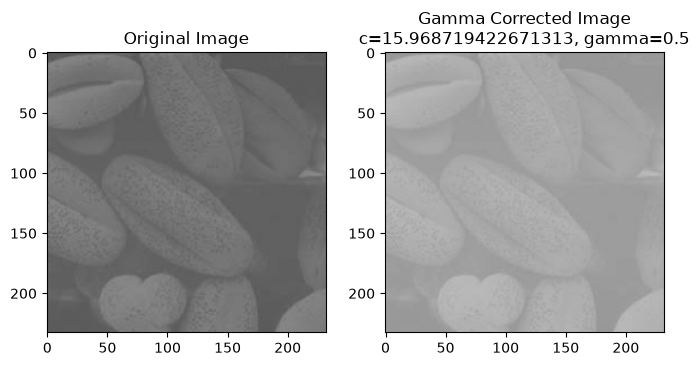

In [39]:
# Displaying Results
fig = plt.figure(figsize=(8,8))
ax1 = fig.add_subplot(221)
ax2 = fig.add_subplot(222)

ax1.imshow(image, cmap='gray',  vmin=0, vmax=255)
ax1.title.set_text('Original Image')
ax2.imshow(gamma_image, cmap='gray',  vmin=0, vmax=255)
ax2.title.set_text(f'Gamma Corrected Image\nc={c}, gamma={gamma}')
plt.show()

**Contrast Stretching**
* Low contrast image occur often due to improper illumination or non-linearly or small dynamic range of an imaging sensor.
* It increases the dynamic range of grey levels in the image.
It has three cases:
1. **When r1 =s1 and r2=s2, transformation becomes a Linear function.**
2. **When r1=r2, s1=0 and s2=L-1, transformation becomes a thresholding function.**
3. **When (r1, s1) = (rmin, 0) and (r2, s2) = (rmax, L-1), this is known as Min-Max Stretching.**

**Image Thresholding**

In [40]:
# Importing the Libraries & Loading the Image
import cv2
import matplotlib.pyplot as plt
import numpy as np
import warnings
from pathlib import Path

# Automatically find the root "Images" folder from week 2
IMG_DIR = None
for candidate in [Path.cwd() / "Images", Path.cwd() / "images", Path.cwd().parent / "Images", Path.cwd().parent / "images"]:
    if candidate.is_dir():
        IMG_DIR = candidate.resolve()
        break

image = cv2.imread(str(IMG_DIR / "road.bmp"), cv2.IMREAD_GRAYSCALE)
thresh_value = 128
# Create empty binary image
binary = np.zeros_like(image)
# Loop over each pixel in the image
for i in range(image.shape[0]):
    for j in range(image.shape[1]):
        # Apply thresholding
        if image[i,j] >= thresh_value:
            binary[i,j] = 255
        else:
            binary[i,j] = 0

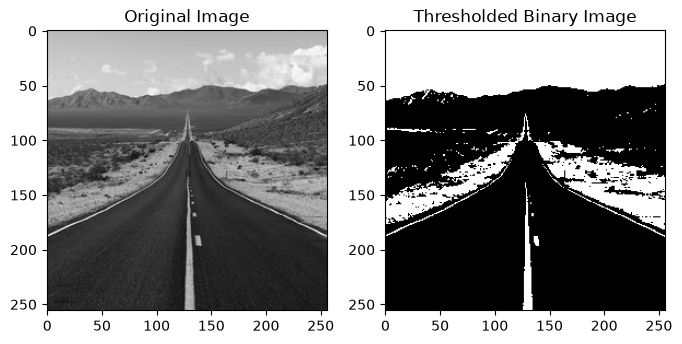

In [41]:
# Displaying Results
fig = plt.figure(figsize=(8,8))
ax1 = fig.add_subplot(221)
ax2 = fig.add_subplot(222)
ax1.imshow(image, cmap='gray',  vmin=0, vmax=255)
ax1.title.set_text('Original Image')
ax2.imshow(binary, cmap='gray',  vmin=0, vmax=255)
ax2.title.set_text('Thresholded Binary Image')
plt.show()

3. **Min-Max Contrast Stretching**

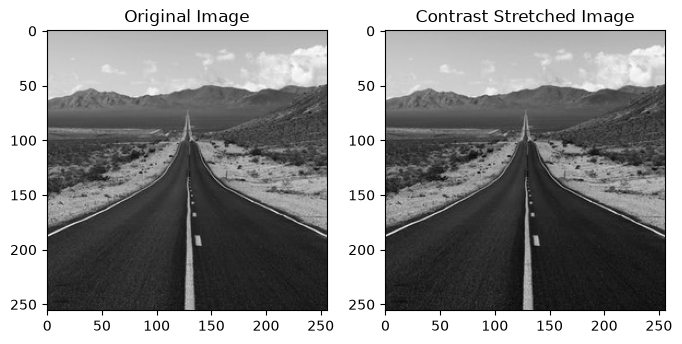

In [42]:
img = cv2.imread(str(IMG_DIR / "Low Contrast.PNG"),cv2.IMREAD_GRAYSCALE)

r1, r2 = image.min(), image.max()
s1, s2 = 0, 255
# Apply the linear transformation using a for loop
output_image = np.zeros_like(image)
for i in range(image.shape[0]):
    for j in range(image.shape[1]):
        output_image[i,j] = (image[i,j] - r1) * ((s2 - s1) / (r2 - r1)) + s1
# Displaying Results
fig = plt.figure(figsize=(8,8))
ax1 = fig.add_subplot(221)
ax2 = fig.add_subplot(222)
ax1.imshow(image, cmap='gray', vmin=0, vmax=255)
ax1.title.set_text('Original Image')
ax2.imshow(output_image, cmap='gray', vmin=0, vmax=255)
ax2.title.set_text('Contrast Stretched Image')
plt.show()

**Intensity Level Slicing**
* Intensity level slicing involves highlighting a specific range of grey level in an image.

* **Case-I:**
1. To display a high value for all gray levels in the range of interest.
2. To display a low value for the rest of gray levels.

* **Case-II:**
1. Brighten the desired range of gray levels.
2. Preserve the rest of the intensity levels remain unchanged as same as the original gray levels.

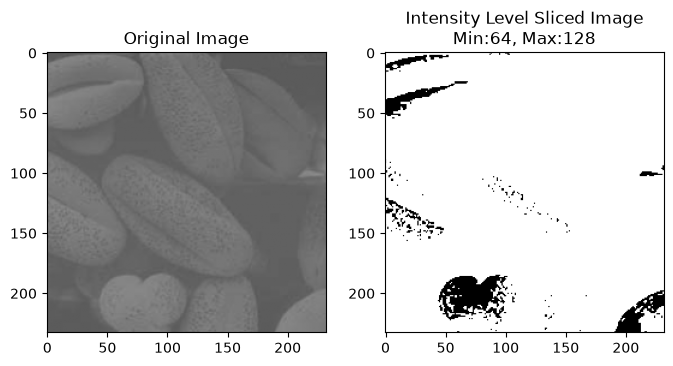

In [45]:
image= cv2.imread(str(IMG_DIR / "Low Contrast.PNG"), cv2.IMREAD_GRAYSCALE)
# Parameters
minimum_range = 64
maximum_range = 128
output_image = np.zeros_like(image)
for i in range(image.shape[0]):
    for j in range(image.shape[1]):
        if image[i,j] > minimum_range and image[i,j] < maximum_range:
            output_image[i,j] = 255
        else:
            output_image[i,j] = 0 # image[i,j] for second case
# Displaying Results
fig = plt.figure(figsize=(8,8))
ax1 = fig.add_subplot(221)
ax2 = fig.add_subplot(222)

ax1.imshow(image, cmap='gray', vmin=0, vmax=255)
ax1.title.set_text('Original Image')
ax2.imshow(output_image, cmap='gray', vmin=0, vmax=255)
ax2.title.set_text(f'Intensity Level Sliced Image\nMin:{minimum_range}, Max:{maximum_range}')
plt.show()

# **Thank You :)**

